# Data Mining Techniques in Python (WEKA Project Reproduced)

This notebook rebuilds my WEKA data mining project in Python, using the same five ARFF datasets that ship with WEKA. Each section mirrors one part of the original project:

| Dataset | Task | Methods |
|---|---|---|
| Iris | Classification and clustering | Naive Bayes, 1-nearest neighbor (IB1), OneR; k-means, hierarchical clustering |
| Breast Cancer | Binary classification | Logistic regression vs Winnow |
| CPU | Regression | Simple vs multiple linear regression |
| Supermarket | Association rules | Apriori |
| Weather | Rule and tree learning | ID3-style decision tree vs PRISM |

Where scikit-learn has no equivalent (OneR, Winnow, PRISM), I implement the algorithm directly in a few lines. All classifiers are scored with 10-fold cross-validation, as in WEKA.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.model_selection import StratifiedKFold, KFold, cross_val_score, cross_val_predict, LeaveOneOut
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, mean_absolute_error, mean_squared_error
from sklearn.tree import DecisionTreeClassifier, export_text
from sklearn.base import BaseEstimator, ClassifierMixin
from mlxtend.frequent_patterns import apriori, association_rules

sns.set_theme(style="whitegrid")
CV = StratifiedKFold(n_splits=10, shuffle=True, random_state=1)

def load(name):
    data, _ = arff.loadarff(f"data/{name}.arff")
    df = pd.DataFrame(data)
    for c in df.select_dtypes(object):
        df[c] = df[c].str.decode("utf-8")
    return df

## 1. Iris: classification

In [2]:
iris = load("iris")
X, y = iris.drop(columns="class"), iris["class"]

class OneR(BaseEstimator, ClassifierMixin):
    """Holte's OneR: pick the single attribute whose bins predict the class best."""
    def __init__(self, bins=6):
        self.bins = bins
    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True); y = pd.Series(y).reset_index(drop=True)
        best = None
        for col in X.columns:
            edges = np.unique(np.quantile(X[col], np.linspace(0, 1, self.bins + 1)))[1:-1]
            b = np.digitize(X[col], edges)
            rule = pd.Series(y.values).groupby(b).agg(lambda s: s.mode()[0])
            acc = (rule.reindex(b).values == y.values).mean()
            if best is None or acc > best[0]:
                best = (acc, col, edges, rule)
        _, self.col_, self.edges_, self.rule_ = best
        self.default_ = y.mode()[0]
        self.classes_ = np.unique(y)
        return self
    def predict(self, X):
        b = np.digitize(pd.DataFrame(X)[self.col_], self.edges_)
        return self.rule_.reindex(b).fillna(self.default_).values

clfs = {"Naive Bayes": GaussianNB(), "IB1 (1-nearest neighbor)": KNeighborsClassifier(1), "OneR": OneR()}
iris_res = pd.Series({n: cross_val_score(m, X, y, cv=CV).mean() for n, m in clfs.items()}, name="10-fold accuracy")
print("OneR picks:", OneR().fit(X, y).col_)
iris_res.round(3).to_frame()

OneR picks: petallength


,10-fold accuracy
Naive Bayes,0.960
IB1 (1-nearest neighbor),0.960
OneR,0.947


## 2. Iris: clustering

The class label is hidden during clustering and used afterwards to check whether the clusters match the species. The adjusted Rand index (ARI) is 1 for a perfect match and about 0 for random assignment.

In [3]:
Xs = (X - X.mean()) / X.std()
clus = {"k-means (k=3)": KMeans(3, n_init=10, random_state=1).fit_predict(Xs),
        "Hierarchical, Ward (k=3)": AgglomerativeClustering(3, linkage="ward").fit_predict(Xs)}
print(pd.Series({n: adjusted_rand_score(y, c) for n, c in clus.items()}, name="ARI vs species").round(3))
pd.crosstab(y, clus["k-means (k=3)"], rownames=["species"], colnames=["k-means cluster"])

k-means (k=3)               0.620
Hierarchical, Ward (k=3)    0.615
Name: ARI vs species, dtype: float64


k-means cluster,0,1,2
species,,,
Iris-setosa,50,0,0
Iris-versicolor,0,39,11
Iris-virginica,0,14,36


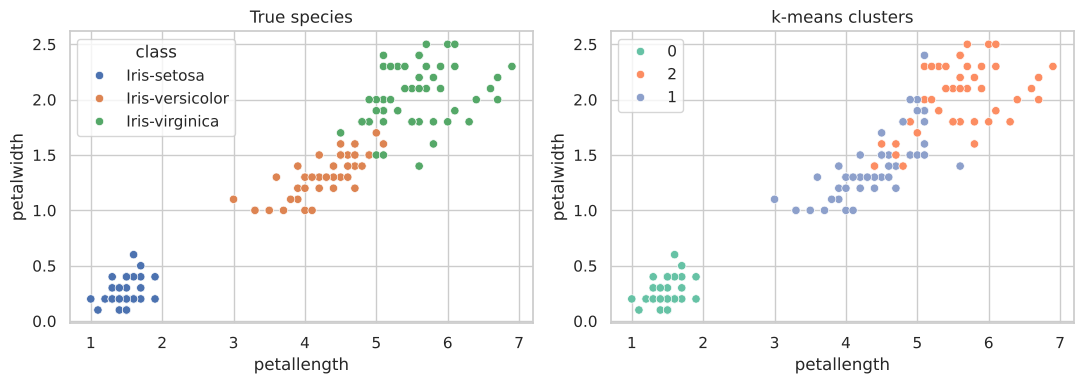

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=iris, x="petallength", y="petalwidth", hue="class", ax=ax[0]); ax[0].set_title("True species")
sns.scatterplot(x=iris["petallength"], y=iris["petalwidth"], hue=clus["k-means (k=3)"].astype(str), palette="Set2", ax=ax[1])
ax[1].set_title("k-means clusters")
plt.tight_layout(); plt.savefig("images/iris_clusters.png", dpi=120); plt.show()

Setosa forms its own cluster perfectly. Versicolor and virginica overlap, so the clusterers mix some of them, which is why ARI is well below 1.

## 3. Breast Cancer: logistic regression vs Winnow

All attributes are nominal, so they are one-hot encoded into binary features. Missing values (`?`) are kept as their own category. Winnow is a mistake-driven linear classifier for binary features that updates weights multiplicatively.

In [5]:
bc = load("breast-cancer")
Xb = pd.get_dummies(bc.drop(columns="Class")).astype(int)
yb = (bc["Class"] == "recurrence-events").astype(int)
print(Xb.shape, "| recurrence rate:", round(yb.mean(), 3))

class Winnow(BaseEstimator, ClassifierMixin):
    """Littlestone's Winnow2 for binary features."""
    def __init__(self, alpha=2.0, epochs=5):
        self.alpha, self.epochs = alpha, epochs
    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        self.w_ = np.ones(X.shape[1]); self.theta_ = X.shape[1] / 2
        for _ in range(self.epochs):
            for xi, yi in zip(X, y):
                pred = int(self.w_ @ xi > self.theta_)
                if pred != yi:
                    self.w_[xi == 1] *= self.alpha if yi == 1 else 1 / self.alpha
        self.classes_ = np.array([0, 1])
        return self
    def predict(self, X):
        return (np.asarray(X) @ self.w_ > self.theta_).astype(int)

bc_res = pd.Series({
    "Majority class (baseline)": (1 - yb.mean()),
    "Logistic regression": cross_val_score(LogisticRegression(C=0.3, max_iter=2000), Xb, yb, cv=CV).mean(),
    "Winnow": cross_val_score(Winnow(), Xb, yb, cv=CV).mean(),
}, name="10-fold accuracy")
bc_res.round(3).to_frame()

(286, 43) | recurrence rate: 0.297


,10-fold accuracy
Majority class (baseline),0.703
Logistic regression,0.731
Winnow,0.700


This dataset is hard: always predicting no recurrence already scores about 70%. Logistic regression is the more reliable of the two learners. Winnow's online, mistake-driven updates are noisy on so few, overlapping examples.

## 4. CPU: simple vs multiple linear regression

Predict relative CPU performance from hardware specs. WEKA reports the correlation between predicted and actual values, so I report that too, from 10-fold cross-validated predictions.

In [6]:
cpu = load("cpu")
Xc, yc = cpu.drop(columns="class"), cpu["class"]
kf = KFold(10, shuffle=True, random_state=1)

def scores(cols):
    p = cross_val_predict(LinearRegression(), Xc[cols], yc, cv=kf)
    return {"correlation": np.corrcoef(p, yc)[0, 1], "MAE": mean_absolute_error(yc, p),
            "RMSE": mean_squared_error(yc, p) ** 0.5}

single = pd.DataFrame({c: scores([c]) for c in Xc.columns}).T.sort_values("correlation", ascending=False)
best_col = single.index[0]
cpu_res = pd.DataFrame({f"Simple LR ({best_col})": scores([best_col]),
                        "Multiple LR (all 6)": scores(list(Xc.columns))}).T.round(3)
cpu_res

,correlation,MAE,RMSE
Simple LR (MMAX),0.853,51.581,83.826
Multiple LR (all 6),0.908,40.654,67.154


In [7]:
coef = pd.Series(LinearRegression().fit(Xc, yc).coef_, index=Xc.columns)
(coef * Xc.std()).sort_values().round(1).to_frame("effect of +1 std")

,effect of +1 std
CHMIN,-1.8
MYCT,12.7
CACH,26.1
CHMAX,38.5
MMIN,59.3
MMAX,65.3


Multiple regression explains performance much better than any single spec. Scaled by each attribute's spread, maximum and minimum main memory (MMAX, MMIN) and maximum channels (CHMAX) have the largest positive effects, with cache (CACH) next.

## 5. Supermarket: association rules with Apriori

Each row is a shopping basket; each column is a product department marked `t` if bought. I keep the 216 department columns and drop the `total` spend band.

In [8]:
sm = load("supermarket")
basket = (sm.drop(columns="total") == "t")
print(basket.shape, "| average items per basket:", round(basket.sum(axis=1).mean(), 1))
freq = apriori(basket, min_support=0.10, use_colnames=True, max_len=5)
rules = association_rules(freq, metric="confidence", min_threshold=0.9)
rules["antecedents"] = rules["antecedents"].map(lambda s: ", ".join(sorted(s)))
rules["consequents"] = rules["consequents"].map(lambda s: ", ".join(sorted(s)))
print(len(rules), "rules with support >= 10% and confidence >= 90%")
rules.sort_values(["confidence", "lift"], ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].head(10).round(3)

(4627, 216) | average items per basket: 18.5


31 rules with support >= 10% and confidence >= 90%


,antecedents,consequents,support,confidence,lift
19,"beef, biscuits, tissues-paper prd, vegetables",bread and cake,0.105,0.912,1.267
10,"biscuits, canned fruit, frozen foods, fruit",bread and cake,0.104,0.909,1.263
11,"biscuits, canned fruit, fruit, vegetables",bread and cake,0.108,0.909,1.263
14,"biscuits, canned vegetables, fruit, milk-cream",bread and cake,0.115,0.908,1.261
30,"beef, milk-cream, tissues-paper prd, vegetables",bread and cake,0.108,0.907,1.260
27,"fruit, margarine, milk-cream, pet foods",bread and cake,0.112,0.907,1.260
1,"biscuits, frozen foods, small goods",bread and cake,0.111,0.906,1.259
21,"beef, biscuits, fruit, milk-cream",bread and cake,0.110,0.906,1.258
3,"canned fruit, milk-cream, tissues-paper prd",bread and cake,0.102,0.906,1.258
13,"biscuits, canned vegetables, fruit, party snac...",bread and cake,0.105,0.905,1.258


In [9]:
bb = rules[rules["antecedents"].str.contains("biscuits") & (rules["consequents"] == "bread and cake")]
bb.sort_values("confidence", ascending=False)[["antecedents", "consequents", "support", "confidence", "lift"]].head(5).round(3)

,antecedents,consequents,support,confidence,lift
19,"beef, biscuits, tissues-paper prd, vegetables",bread and cake,0.105,0.912,1.267
10,"biscuits, canned fruit, frozen foods, fruit",bread and cake,0.104,0.909,1.263
11,"biscuits, canned fruit, fruit, vegetables",bread and cake,0.108,0.909,1.263
14,"biscuits, canned vegetables, fruit, milk-cream",bread and cake,0.115,0.908,1.261
1,"biscuits, frozen foods, small goods",bread and cake,0.111,0.906,1.259


Every strong rule predicts bread and cake, the most common department. The best rules reach about 91% confidence with lift 1.27, close to the WEKA result (92% confidence, lift 1.27): a basket with biscuits plus a few other staples is 27% more likely than average to include bread and cake.

## 6. Weather: decision tree vs PRISM rules

With only 14 examples, the goal is to compare how the two methods describe the data. Accuracy uses leave-one-out cross-validation.

In [10]:
w = load("weather.nominal")
Xw, yw = w.drop(columns="play"), w["play"]
Xw1 = pd.get_dummies(Xw).astype(int)
tree = DecisionTreeClassifier(criterion="entropy", random_state=1).fit(Xw1, yw)
print(export_text(tree, feature_names=list(Xw1.columns)))

|--- outlook_overcast <= 0.50
|   |--- humidity_high <= 0.50
|   |   |--- windy_TRUE <= 0.50
|   |   |   |--- class: yes
|   |   |--- windy_TRUE >  0.50
|   |   |   |--- outlook_rainy <= 0.50
|   |   |   |   |--- class: yes
|   |   |   |--- outlook_rainy >  0.50
|   |   |   |   |--- class: no
|   |--- humidity_high >  0.50
|   |   |--- outlook_sunny <= 0.50
|   |   |   |--- windy_FALSE <= 0.50
|   |   |   |   |--- class: no
|   |   |   |--- windy_FALSE >  0.50
|   |   |   |   |--- class: yes
|   |   |--- outlook_sunny >  0.50
|   |   |   |--- class: no
|--- outlook_overcast >  0.50
|   |--- class: yes



In [11]:
class Prism(BaseEstimator, ClassifierMixin):
    """Cendrowska's PRISM covering algorithm for nominal attributes."""
    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True); y = pd.Series(y).reset_index(drop=True)
        self.rules_ = []
        for cls in y.unique():
            remaining = X.copy(); ry = y.copy()
            while (ry == cls).any():
                conds, cover, cy = {}, remaining, ry
                while (cy != cls).any() and len(conds) < X.shape[1]:
                    best = max(((a, v) for a in X.columns if a not in conds for v in cover[a].unique()),
                               key=lambda av: ((cy[cover[av[0]] == av[1]] == cls).mean(),
                                               (cy[cover[av[0]] == av[1]] == cls).sum()))
                    conds[best[0]] = best[1]
                    m = cover[best[0]] == best[1]; cover, cy = cover[m], cy[m]
                self.rules_.append((conds, cls))
                covered = np.logical_and.reduce([remaining[a] == v for a, v in conds.items()])
                remaining, ry = remaining[~covered], ry[~covered]
        self.default_ = y.mode()[0]; self.classes_ = np.unique(y)
        return self
    def predict(self, X):
        X = pd.DataFrame(X)
        out = []
        for _, row in X.iterrows():
            out.append(next((c for conds, c in self.rules_ if all(row[a] == v for a, v in conds.items())), self.default_))
        return np.array(out)

prism = Prism().fit(Xw, yw)
for conds, cls in prism.rules_:
    print("IF " + " AND ".join(f"{a} = {v}" for a, v in conds.items()) + f"  THEN play = {cls}")

IF outlook = sunny AND humidity = high  THEN play = no
IF outlook = rainy AND windy = TRUE  THEN play = no
IF outlook = overcast  THEN play = yes
IF humidity = normal AND windy = FALSE  THEN play = yes
IF temperature = mild AND humidity = normal  THEN play = yes
IF outlook = rainy AND windy = FALSE  THEN play = yes


In [12]:
loo = LeaveOneOut()
pd.Series({"Decision tree (entropy, ID3-style)": cross_val_score(DecisionTreeClassifier(criterion="entropy", random_state=1), Xw1, yw, cv=loo).mean(),
           "PRISM": cross_val_score(Prism(), Xw, yw, cv=loo).mean()}, name="leave-one-out accuracy").round(3).to_frame()

,leave-one-out accuracy
"Decision tree (entropy, ID3-style)",0.5
PRISM,1.0


Both methods find the same structure (outlook first; humidity matters when sunny, wind matters when rainy). The tree expresses it as one hierarchy, while PRISM gives independent IF-THEN rules that are easier to read one at a time. PRISM happens to classify all 14 held-out examples correctly while the tree gets half right, but with 14 examples a single case moves accuracy by 7 points, so this says little about the methods in general.

## Summary

| Dataset | Result |
|---|---|
| Iris | Naive Bayes and IB1 both 96% accurate; OneR on petal length alone reaches 95%. Setosa clusters perfectly; versicolor and virginica overlap (ARI 0.62) |
| Breast Cancer | Hard data: the majority class scores 70%. Logistic regression reaches 73%; Winnow does no better than the baseline |
| CPU | Multiple regression: correlation 0.91 vs 0.85 for the best single spec (MMAX) |
| Supermarket | 31 rules at 90%+ confidence, all predicting bread and cake (lift about 1.26) |
| Weather | Tree and PRISM find the same patterns in different forms |